# A02-DB — Thuận

Phân công khớp chính xác mốc `2026-11-17T21:00:00.000Z` trong workbook nguồn.
Ngày giờ Việt Nam: **04:00 ngày 18/11/2026**. Mã thư mục giữ ngày của mốc UTC.

Cấu hình: `A02`, `DBSCAN`. Nguồn duy nhất:
`data/raw/Online Retail.xlsx`, SHA-256 `43465a06f2ccf7c8b5bd2892bc7defb52f97487934fe93b16ae4c3936424676d`.

Notebook mặc định đọc kết quả đã chạy. Đổi `RUN_AGAIN = True` để dựng lại từ raw,
quét tham số và ghi lại **chỉ thư mục kết quả của thí nghiệm này**.
Mọi nhãn cụm gắn với CustomerID; Monetary là giá trị mua lịch sử GBP.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

REL = Path("project/experiments/thuan_deadline_2026_11_17")
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in [p, p / REL]]
BASE = next(q for q in candidates if (q / "run_experiments.py").is_file())
if str(BASE) not in sys.path: sys.path.insert(0, str(BASE))
import run_experiments as runner


In [2]:
EXPERIMENT = "A02-DB"
RUN_AGAIN = False
if RUN_AGAIN:
    with threadpool_limits(limits=1):
        rfm, cleaning, provenance = runner.prepare_input()
        runner.run_one(EXPERIMENT, rfm)
        runner.workbook(runner.assignments(), rfm, cleaning, provenance)
OUT = BASE / "results" / EXPERIMENT
params = json.loads((OUT / "parameters.json").read_text(encoding="utf-8"))
assert params["status"] == "completed"
display(pd.Series({
    "Thí nghiệm": EXPERIMENT,
    "Mô hình": params["actual_model"],
    "Khách": params["customers"],
    "Số chiều đầu vào": params["preprocessing"]["model_input_dimensions"],
    "Biến đổi": params["preprocessing"]["transform"],
    "Scaler": params["preprocessing"]["scaler"],
    "PCA": params["preprocessing"]["pca_requested"],
}).to_frame("Giá trị"))
print(json.dumps(params["preprocessing"], ensure_ascii=False, indent=2))


,Giá trị
Thí nghiệm,A02-DB
Mô hình,DBSCAN
Khách,4327
Số chiều đầu vào,3
Biến đổi,none
Scaler,StandardScaler
PCA,None


{
  "configuration": "A02",
  "transform": "none",
  "scaler": "StandardScaler",
  "pca_requested": null,
  "model_input_dimensions": 3
}


## Quét tham số và lựa chọn
GN dùng GNN Graph Autoencoder hai lớp GCN rồi K-Means trên embedding học được. Silhouette GN tính trên embedding; KM tính trên PCA/scaler input; DBSCAN tính trên khách không nhiễu. Các không gian này không so trực tiếp. Checkpoint GNN chọn theo BCE validation, không theo test.

,Được chọn
eps,1.5
min_samples,4
n_clusters,3
noise_pct,0.415993
smallest_cluster,4
largest_cluster_pct_all,99.399122
silhouette,0.817703
dbi,0.404551
chi,181.772171
warnings,


,eps,min_samples,n_clusters,noise_pct,smallest_cluster,largest_cluster_pct_all,silhouette,dbi,chi,warnings,eligible
0,0.1,4,39,9.221169,3,31.892766,-0.299787,1.498550,118.360850,NaN,False
1,0.2,4,5,3.351052,4,95.978738,0.331426,0.544928,42.865430,NaN,True
2,0.3,4,2,2.287959,8,97.527155,0.666754,0.304129,96.244497,NaN,True
3,0.4,4,1,1.594638,4258,98.405362,NaN,NaN,NaN,NaN,False
4,0.5,4,1,1.109314,4279,98.890686,NaN,NaN,NaN,NaN,False
5,0.7,4,1,0.970649,4285,99.029351,NaN,NaN,NaN,NaN,False
6,1.0,4,1,0.693321,4297,99.306679,NaN,NaN,NaN,NaN,False
7,1.5,4,3,0.415993,4,99.399122,0.817703,0.404551,181.772171,NaN,True
8,2.0,4,1,0.346661,4312,99.653339,NaN,NaN,NaN,NaN,False
9,0.1,6,22,11.670904,6,31.869656,-0.301377,1.830814,190.108415,NaN,False


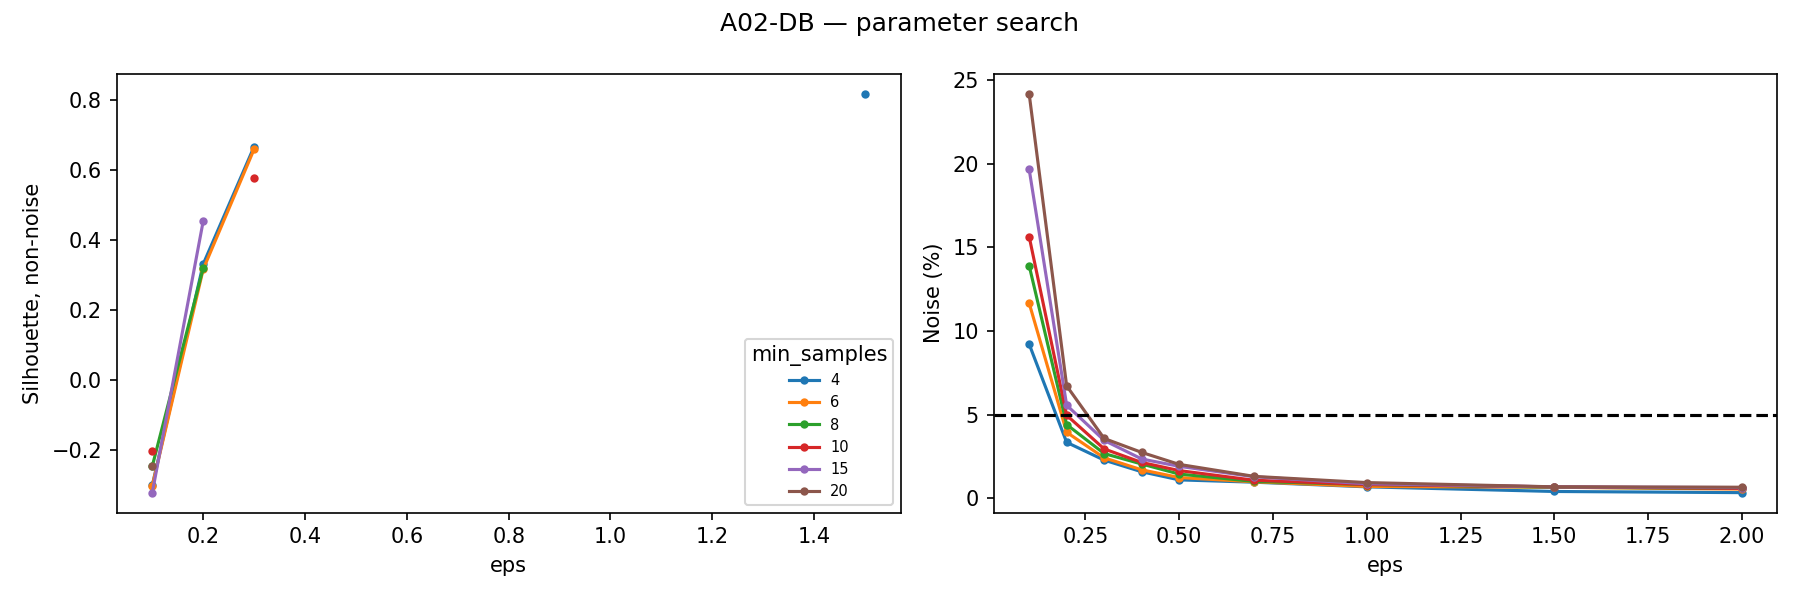

In [3]:
grid = pd.read_csv(OUT / "search.csv")
display(pd.Series(params["selected"]).to_frame("Được chọn"))
display(grid)
display(Image(filename=str(OUT / "figures" / "search.png")))
if "gnn_training" in params:
    print(json.dumps(params["gnn_training"], ensure_ascii=False, indent=2))
    display(Image(filename=str(OUT / "figures" / "training.png")))
    display(pd.read_csv(OUT / "training_history.csv"))


## Nhãn và hồ sơ cụm
Hình chỉ hiển thị hai tọa độ đầu; bảng RFM dùng đơn vị gốc.

,CustomerID,Recency,Frequency,Monetary,cluster
0,12347,3,7,4310.00,0
1,12348,76,4,1437.24,0
2,12349,19,1,1457.55,0
3,12350,311,1,294.40,0
4,12352,37,7,1385.74,0
5,12353,205,1,89.00,0
6,12354,233,1,1079.40,0
7,12355,215,1,459.40,0
8,12356,23,3,2487.43,0
9,12357,34,1,6207.67,0


,cluster,customers,Recency_median,Frequency_median,Monetary_median,Monetary_sum,customer_pct,monetary_pct
0,-1,18,3.0,61.0,63643.155,1613345.880,0.415993,19.170466
1,0,4301,52.0,2.0,654.670,6436225.063,99.399122,76.477981
2,1,4,3.0,54.0,35907.500,137085.890,0.092443,1.628913
3,2,4,4.0,46.0,56282.310,229131.540,0.092443,2.722639


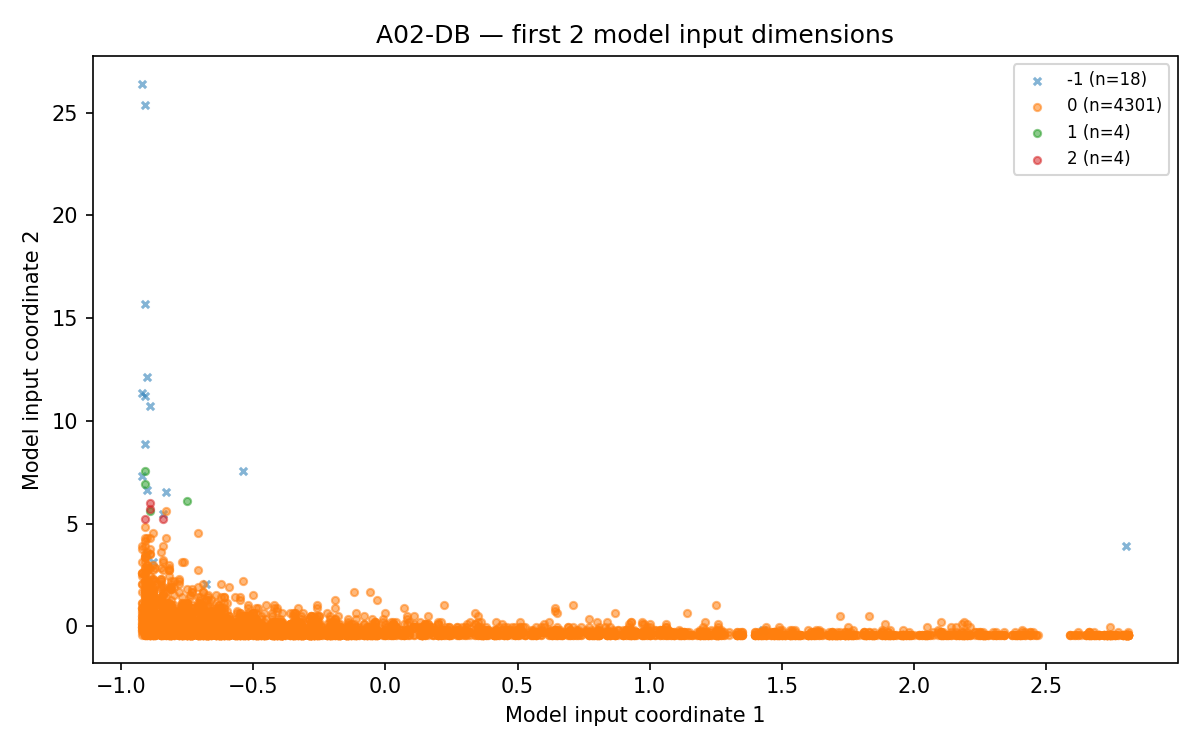

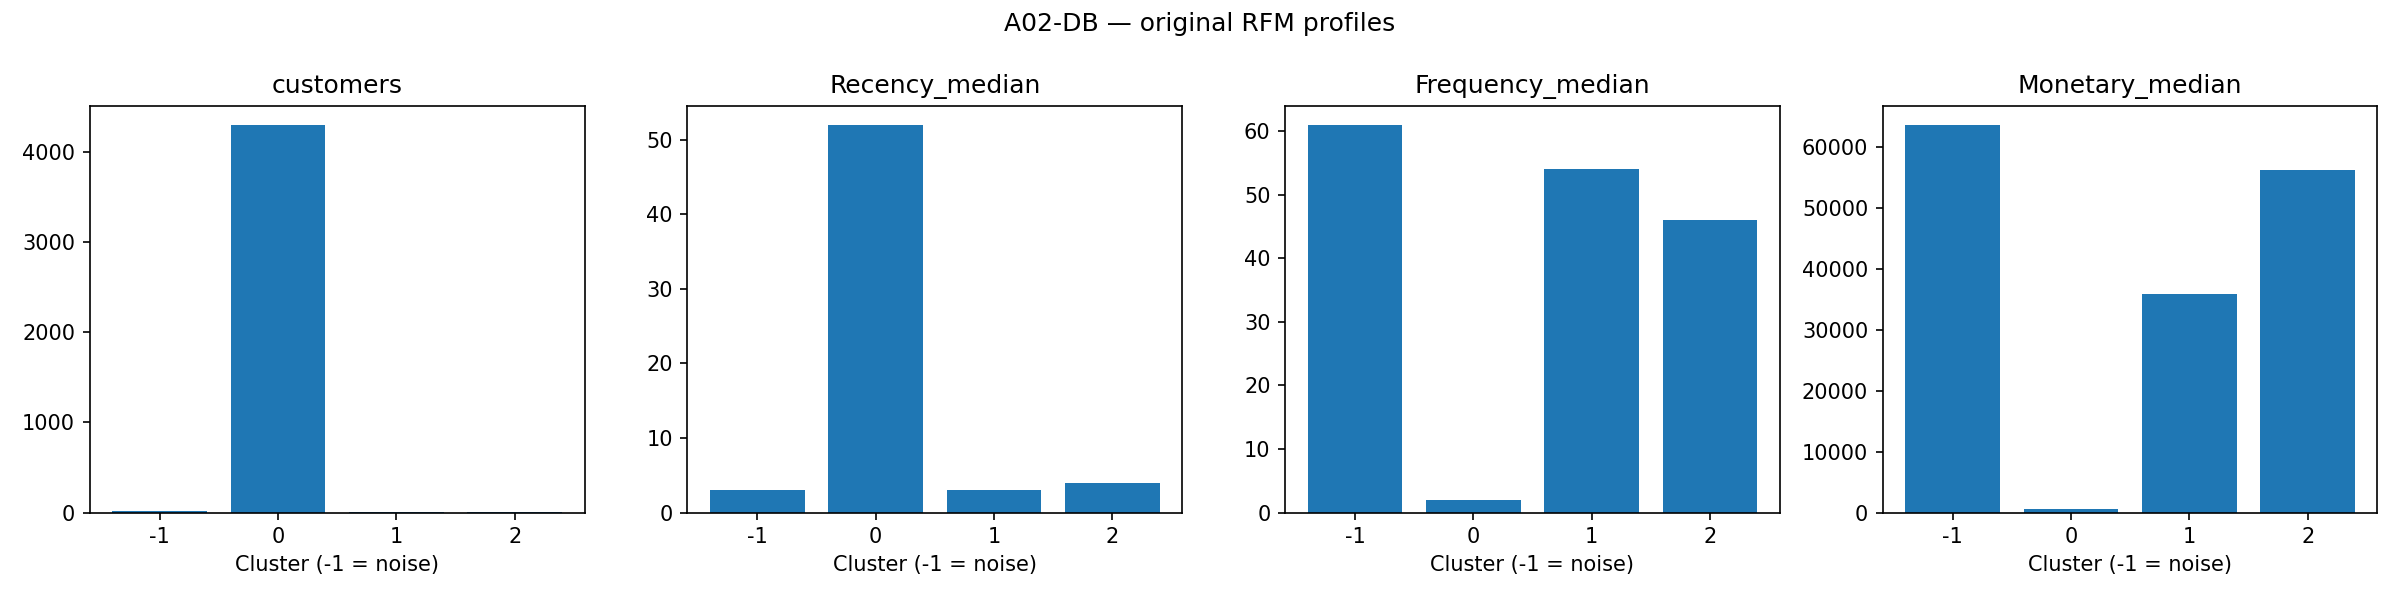

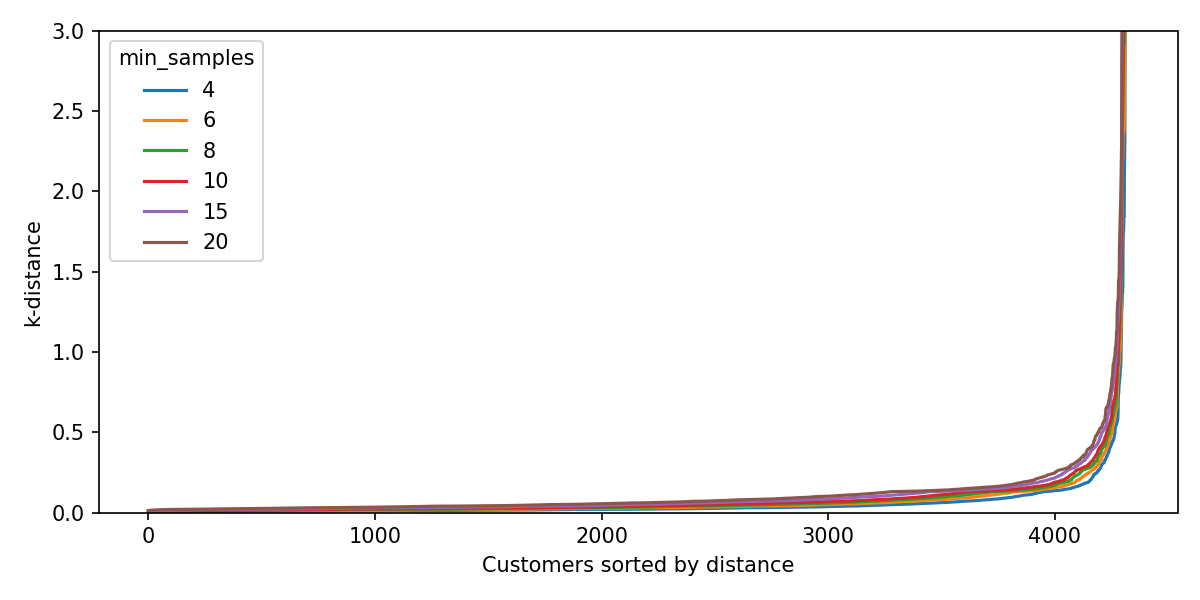

In [4]:
labels = pd.read_csv(OUT / "labels.csv", dtype={"CustomerID": str})
profiles = pd.read_csv(OUT / "profiles.csv")
assert labels.CustomerID.is_unique and len(labels) == params["customers"]
display(labels.head(10))
display(profiles)
display(Image(filename=str(OUT / "figures" / "clusters.png")))
display(Image(filename=str(OUT / "figures" / "profiles.png")))
if (OUT / "figures" / "k_distance.png").exists():
    display(Image(filename=str(OUT / "figures" / "k_distance.png")))


## Đối chiếu và giới hạn
Parent diagnostic giữ tham số đã chọn ở target, không phải baseline được tune độc lập. GNN dùng đồ thị kNN từ RFM, nên AUC/AP liên kết chỉ đánh giá tái dựng graph; không có BIC/AIC. GNN có tính transductive: suy luận chỉ áp dụng tập khách gốc đúng thứ tự.

In [5]:
if params.get("comparison"):
    print(json.dumps(params["comparison"], ensure_ascii=False, indent=2))
print("Chỉ số trên StandardScaler(RFM gốc), dùng cùng không gian tham chiếu:")
display(pd.Series(params["all_customers_common_space_scores"]).to_frame("Giá trị"))
display(Markdown("\n".join("- " + note for note in params["limitations"])))


{
  "parent_configuration": "A01",
  "purpose": "fixed-parameter preprocessing diagnostic, not a tuned parent experiment",
  "target_dimensions": 3,
  "parent_dimensions": 3,
  "ari": 1.0,
  "target_common_rfm_scores": {
    "n_clusters": 3,
    "noise_pct": 0.4159926045759187,
    "smallest_cluster": 4,
    "largest_cluster_pct_all": 99.39912179339034,
    "silhouette": 0.8177029258485679,
    "dbi": 0.40455148524808054,
    "chi": 181.77217103830702
  },
  "parent_common_rfm_scores": {
    "n_clusters": 3,
    "noise_pct": 0.4159926045759187,
    "smallest_cluster": 4,
    "largest_cluster_pct_all": 99.39912179339034,
    "silhouette": 0.8177029258485679,
    "dbi": 0.40455148524808054,
    "chi": 181.77217103830702
  },
  "parent_input_scores": {
    "n_clusters": 3,
    "noise_pct": 0.4159926045759187,
    "smallest_cluster": 4,
    "largest_cluster_pct_all": 99.39912179339034,
    "silhouette": 0.8177029258485679,
    "dbi": 0.40455148524807755,
    "chi": 181.77217103830722
  },


,Giá trị
n_clusters,3.000000
noise_pct,0.415993
smallest_cluster,4.000000
largest_cluster_pct_all,99.399122
silhouette,0.817703
dbi,0.404551
chi,181.772171


- Exploratory clustering, not future value prediction; Monetary is historical sales, not profit.
- No ground-truth labels or held-out predictive evaluation.
- Internal scores from different feature spaces and DBSCAN subsets are not directly comparable.
- The cleaning policy reproduces the shared group RFM; it is not a newly approved official policy.
- Largest cluster contains at least 90% of customers; high Silhouette alone does not imply a useful segmentation.
- A selected cluster contains less than 1% of customers; inspect profiles before use.

## Kiểm tra mô hình đã lưu

In [6]:
import joblib
pipeline = joblib.load(OUT / "pipeline.joblib")
X = labels[runner.FEATURES]
Z = pipeline["preprocessing"].transform(X)
saved = pd.read_csv(OUT / "model_input.csv").filter(like="input_").to_numpy()
np.testing.assert_allclose(Z, saved, atol=1e-9, rtol=0)
if params["actual_model"] != "DBSCAN":
    np.testing.assert_array_equal(pipeline.predict(X), labels.cluster)
else:
    np.testing.assert_array_equal(pipeline["model"].labels_, labels.cluster)
    print("DBSCAN không có predict cho khách mới; labels_ gắn với đúng thứ tự khách khi fit.")
print("PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.")


DBSCAN không có predict cho khách mới; labels_ gắn với đúng thứ tự khách khi fit.
PASS — mô hình lưu, dữ liệu đầu vào và nhãn khớp nhau.
